# DataVine Analytics — Machine Learning Projects

**Richard Okello** · [@RichWOkello](https://github.com/RichWOkello)

This notebook develops three machine learning applications using the Wine, Chickwts, and USArrests datasets:

- **Wine classification:** Predict wine classes from chemical attributes using k-Nearest Neighbors (k-NN), Principal Component Analysis (PCA), and hyperparameter tuning.
- **Agricultural feed recommendation:** Evaluate feed-level similarity using standardized weights, one-component PCA, and cosine similarity.
- **Regional crime pattern analysis:** Investigate historical state-level crime patterns through feature selection, PCA, K-Means, and Gaussian Mixture Models (GMM).

The workflow covers Exploratory Data Analysis (EDA), data preprocessing, model development, validation, and interpretation. A fixed random state (`42`) supports reproducibility. All three CSV files are read from the notebook directory.

**Scope:** Wine classes represent cultivars rather than quality ratings. Feed comparisons reflect observed weights and do not establish causality. USArrests contains historical observations and should not be interpreted as current crime conditions.

## 1. Environment setup

The analysis uses **pandas** and **NumPy** for data processing, **Matplotlib** and **Seaborn** for visualization, and **scikit-learn** for PCA, classification, similarity estimation, and clustering. Wine preprocessing is included within the cross-validation pipeline to prevent data leakage.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    silhouette_score, adjusted_rand_score,
)
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 130)
print("Environment ready — pandas:", pd.__version__)
print("Working directory:", Path.cwd().resolve())

Environment ready — pandas: 2.2.3
Working directory: /mnt/data/datavine-analytics-summative-lab


## 2. Data preparation and EDA

Initial data quality checks cover dataset dimensions, variable types, missing values, duplicate rows, and feature distributions. Descriptive statistics and visualizations support Exploratory Data Analysis (EDA) before model selection.

Repeated observations in Chickwts may represent different chickens with identical weight and feed values; therefore, duplicate records are retained. Median imputation addresses missing numerical values when necessary, while **StandardScaler** standardizes numerical features before distance-based methods and PCA.

In [2]:
files = {"Wine": "wine.csv", "Chickwts": "chickwts.csv", "USArrests": "USArrests.csv"}
missing_files = [file for file in files.values() if not Path(file).is_file()]
if missing_files:
    raise FileNotFoundError(
        f"Missing {missing_files}. Place the three original CSV files next to this notebook and run again."
    )

wine = pd.read_csv(files["Wine"])
chick = pd.read_csv(files["Chickwts"])
arrests = pd.read_csv(files["USArrests"])
datasets = {"Wine": wine, "Chickwts": chick, "USArrests": arrests}

quality = []
for name, frame in datasets.items():
    quality.append({
        "Dataset": name, "Rows": len(frame), "Columns": frame.shape[1],
        "Missing cells": int(frame.isna().sum().sum()),
        "Duplicate rows": int(frame.duplicated().sum()),
        "Numeric columns": frame.select_dtypes(include=np.number).shape[1],
    })
    print(f"\n{name} | shape = {frame.shape}")
    display(frame.head(3))
    display(pd.DataFrame({"dtype": frame.dtypes.astype(str), "missing": frame.isna().sum(),
                          "unique": frame.nunique(dropna=False)}))

quality_table = pd.DataFrame(quality).set_index("Dataset")
print("Dataset quality overview:")
display(quality_table)

assert {"target"}.issubset(wine.columns)
assert {"weight", "feed"}.issubset(chick.columns)
assert {"rownames", "Murder", "Assault", "UrbanPop", "Rape"}.issubset(arrests.columns)
assert wine["target"].notna().all(), "Wine target must not be missing."
assert chick["feed"].notna().all(), "Feed identifier must not be missing."
assert arrests["rownames"].notna().all(), "State names must not be missing."


Wine | shape = (178, 14)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0


,dtype,missing,unique
alcohol,float64,0,126
malic_acid,float64,0,133
ash,float64,0,79
alcalinity_of_ash,float64,0,63
magnesium,float64,0,53
total_phenols,float64,0,97
flavanoids,float64,0,132
nonflavanoid_phenols,float64,0,39
proanthocyanins,float64,0,101
color_intensity,float64,0,132



Chickwts | shape = (71, 2)


,weight,feed
0,179,horsebean
1,160,horsebean
2,136,horsebean


,dtype,missing,unique
weight,int64,0,66
feed,object,0,6



USArrests | shape = (50, 5)


,rownames,Murder,Assault,UrbanPop,Rape
0,Alabama,13.2,236,58,21.2
1,Alaska,10.0,263,48,44.5
2,Arizona,8.1,294,80,31.0


,dtype,missing,unique
rownames,object,0,50
Murder,float64,0,43
Assault,int64,0,45
UrbanPop,int64,0,36
Rape,float64,0,48


Dataset quality overview:


,Rows,Columns,Missing cells,Duplicate rows,Numeric columns
Dataset,,,,,
Wine,178,14,0,0,14
Chickwts,71,2,0,1,1
USArrests,50,5,0,0,4


### 2.1 Exploratory Data Analysis (EDA)

The EDA includes class frequencies for Wine, weight distributions by feed type for Chickwts, and a Pearson correlation heatmap for USArrests. These summaries help identify class imbalance, differences in group distributions, and relationships among numerical variables. Descriptive statistics provide additional context for subsequent modeling.

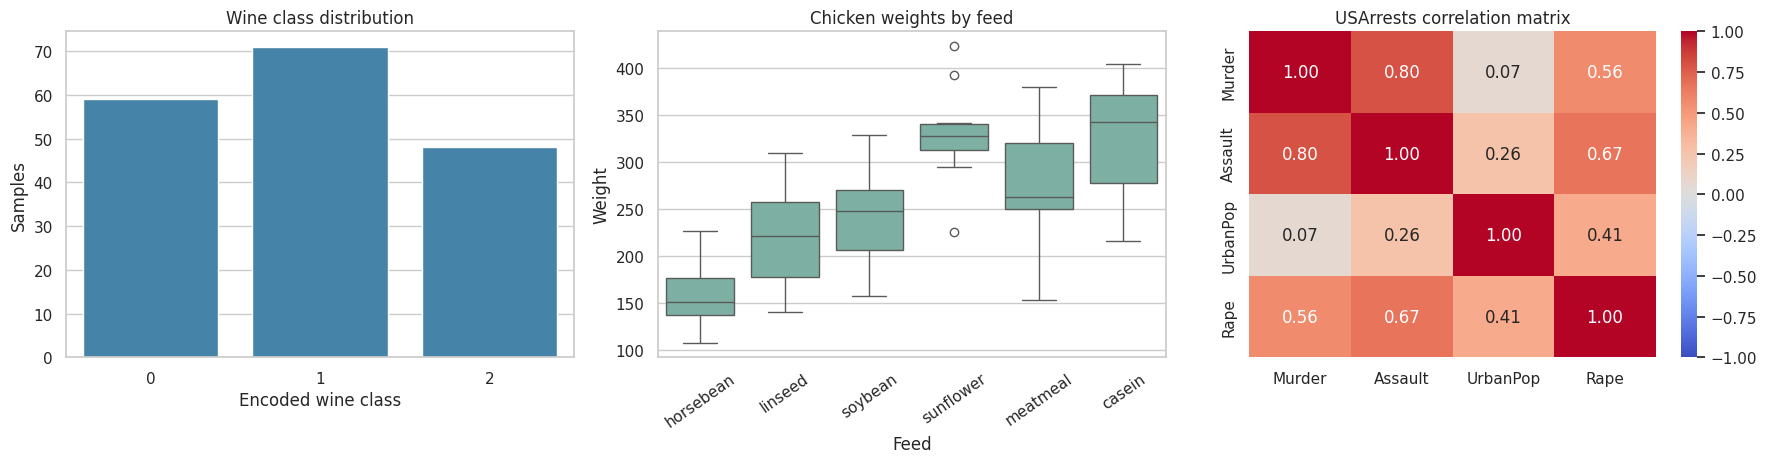

Wine target counts:


,count
target,
0,59
1,71
2,48


Feed sample count and weight descriptive statistics:


,count,mean,std,median,min,max
feed,,,,,,
casein,12,323.58,64.43,342.0,216,404
horsebean,10,160.20,38.63,151.5,108,227
linseed,12,218.75,52.24,221.0,141,309
meatmeal,11,276.91,64.90,263.0,153,380
soybean,14,246.43,54.13,248.0,158,329
sunflower,12,328.92,48.84,328.0,226,423


Arrest-data feature summaries:


,Murder,Assault,UrbanPop,Rape
count,50.00,50.00,50.00,50.00
mean,7.79,170.76,65.54,21.23
std,4.36,83.34,14.47,9.37
min,0.80,45.00,32.00,7.30
25%,4.08,109.00,54.50,15.08
50%,7.25,159.00,66.00,20.10
75%,11.25,249.00,77.75,26.18
max,17.40,337.00,91.00,46.00


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
sns.countplot(data=wine, x="target", color="#3487b8", ax=axes[0])
axes[0].set(title="Wine class distribution", xlabel="Encoded wine class", ylabel="Samples")
sns.boxplot(data=chick, x="feed", y="weight", color="#75b8a7", ax=axes[1])
axes[1].tick_params(axis="x", rotation=35)
axes[1].set(title="Chicken weights by feed", xlabel="Feed", ylabel="Weight")
sns.heatmap(arrests[["Murder", "Assault", "UrbanPop", "Rape"]].corr(),
            annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="coolwarm", ax=axes[2])
axes[2].set(title="USArrests correlation matrix")
plt.tight_layout()
plt.show()

print("Wine target counts:")
display(wine["target"].value_counts().sort_index().rename("count").to_frame())
print("Feed sample count and weight descriptive statistics:")
display(chick.groupby("feed")["weight"].agg(["count", "mean", "std", "median", "min", "max"]).round(2))
print("Arrest-data feature summaries:")
display(arrests[["Murder", "Assault", "UrbanPop", "Rape"]].describe().round(2))

## 3. Wine classification: PCA and k-NN

Wine class is predicted from the available chemical measurements. **LabelEncoder** converts the target labels into numerical class identifiers. A **stratified 75:25 train–test split** preserves class proportions and reserves an independent dataset for final evaluation.

A scikit-learn **Pipeline** performs median imputation, feature standardization, **PCA with at least 95% explained variance**, and k-Nearest Neighbors (**k-NN**) classification. **GridSearchCV**, using five-fold **StratifiedKFold** cross-validation, tunes `n_neighbors`, the distance metric (Euclidean or Manhattan), and the weighting scheme (uniform or distance). All preprocessing is fitted within each training fold to minimize information leakage.

In [4]:
X_wine = wine.drop(columns="target").select_dtypes(include=np.number)
raw_target = wine["target"].astype(str)
label_encoder = LabelEncoder()
y_wine = label_encoder.fit_transform(raw_target)
label_mapping = pd.DataFrame({"Original class": label_encoder.classes_,
                              "Encoded class": np.arange(len(label_encoder.classes_))})
print("Wine label encoding (original target is already numeric in the provided CSV):")
display(label_mapping)

X_train, X_test, y_train, y_test = train_test_split(
    X_wine, y_wine, test_size=0.25, random_state=RANDOM_STATE, stratify=y_wine
)
print(f"Training rows: {len(X_train)} | Test rows: {len(X_test)} | Chemical predictors: {X_train.shape[1]}")

wine_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    ("pca", PCA(n_components=0.95, svd_solver="full")),
    ("knn", KNeighborsClassifier()),
])

wine_grid = {
    "knn__n_neighbors": [1, 3, 5, 7, 9, 11],
    "knn__metric": ["euclidean", "manhattan"],
    "knn__weights": ["uniform", "distance"],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grid_search = GridSearchCV(
    estimator=wine_pipeline, param_grid=wine_grid, scoring="accuracy",
    cv=cv, n_jobs=1, refit=True, return_train_score=True,
)
grid_search.fit(X_train, y_train)
wine_best = grid_search.best_estimator_
print("Best parameters:", grid_search.best_params_)
print(f"Best mean validation accuracy (5-fold CV): {grid_search.best_score_:.3f}")
print(f"Selected PCA components: {wine_best.named_steps['pca'].n_components_} / {X_train.shape[1]}")
retained = float(np.sum(wine_best.named_steps["pca"].explained_variance_ratio_))
print(f"Training data variance retained after PCA: {retained:.2%}")
assert retained >= 0.95 - 1e-10

tuned_results = pd.DataFrame(grid_search.cv_results_)[[
    "param_knn__n_neighbors", "param_knn__metric", "param_knn__weights",
    "mean_test_score", "std_test_score", "rank_test_score",
]]
print("Top cross-validation configurations:")
display(tuned_results.sort_values("rank_test_score").head(10).round(3))

Wine label encoding (original target is already numeric in the provided CSV):


,Original class,Encoded class
0,0,0
1,1,1
2,2,2


Training rows: 133 | Test rows: 45 | Chemical predictors: 13


Best parameters: {'knn__metric': 'euclidean', 'knn__n_neighbors': 1, 'knn__weights': 'uniform'}
Best mean validation accuracy (5-fold CV): 0.970
Selected PCA components: 10 / 13
Training data variance retained after PCA: 96.37%
Top cross-validation configurations:


,param_knn__n_neighbors,param_knn__metric,param_knn__weights,mean_test_score,std_test_score,rank_test_score
0,1,euclidean,uniform,0.970,0.043,1
1,1,euclidean,distance,0.970,0.043,1
7,7,euclidean,distance,0.970,0.028,3
9,9,euclidean,distance,0.970,0.028,3
12,1,manhattan,uniform,0.970,0.028,3
13,1,manhattan,distance,0.970,0.028,3
10,11,euclidean,uniform,0.970,0.028,3
4,5,euclidean,uniform,0.963,0.033,8
11,11,euclidean,distance,0.963,0.023,9
8,9,euclidean,uniform,0.963,0.023,9


### 3.1 Model evaluation

The tuned classifier correctly identifies **43 of 45** observations in the held-out test set, corresponding to **95.6% test accuracy**. Five-fold cross-validation accuracy is approximately **97%**.

Evaluation includes the **classification report** (precision, recall, and F1-score), **confusion matrix**, and sample predictions. These metrics provide a broader assessment than accuracy alone. Performance on an operational wine inventory would require additional external validation.

Independent test accuracy: 0.956 (43/45 correct)

Classification report (held-out test set):
              precision    recall  f1-score   support

      Wine 0       0.94      1.00      0.97        15
      Wine 1       1.00      0.89      0.94        18
      Wine 2       0.92      1.00      0.96        12

    accuracy                           0.96        45
   macro avg       0.95      0.96      0.96        45
weighted avg       0.96      0.96      0.96        45



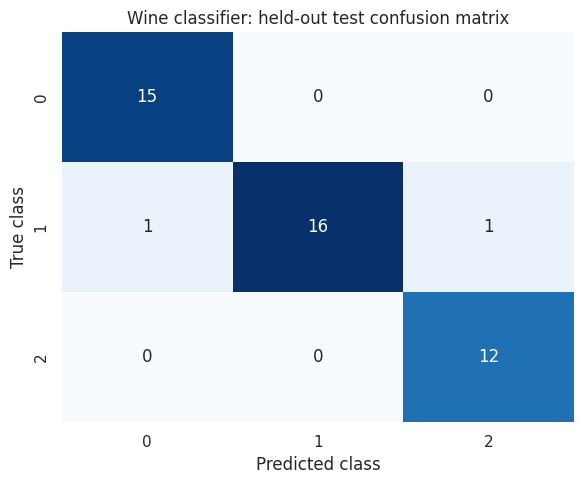

Example test predictions:


,alcohol,color_intensity,Actual class,Predicted class
35,13.48,5.10,0,0
93,12.29,2.15,1,1
7,14.06,5.05,0,0
28,13.87,4.50,0,0
87,11.65,2.60,1,1
42,13.88,5.43,0,0
18,14.19,8.70,0,0
60,12.33,3.27,1,1


In [5]:
y_pred = wine_best.predict(X_test)
wine_test_accuracy = accuracy_score(y_test, y_pred)
print(f"Independent test accuracy: {wine_test_accuracy:.3f} ({np.sum(y_pred == y_test)}/{len(y_test)} correct)")
print("\nClassification report (held-out test set):")
print(classification_report(y_test, y_pred, target_names=[f"Wine {x}" for x in label_encoder.classes_], zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=np.arange(len(label_encoder.classes_)))
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_, ax=ax)
ax.set(title="Wine classifier: held-out test confusion matrix", xlabel="Predicted class", ylabel="True class")
plt.tight_layout()
plt.show()

print("Example test predictions:")
sample_prediction = X_test.head(8).copy()
sample_prediction["Actual class"] = label_encoder.inverse_transform(y_test[:8])
sample_prediction["Predicted class"] = label_encoder.inverse_transform(y_pred[:8])
display(sample_prediction[["alcohol", "color_intensity", "Actual class", "Predicted class"]])

### 3.2 PCA visualization

A two-component PCA projection visualizes the separation among the three wine classes. This projection is used exclusively for EDA and visualization. The tuned classification pipeline independently retains enough principal components to explain at least **95% of training-set variance**.

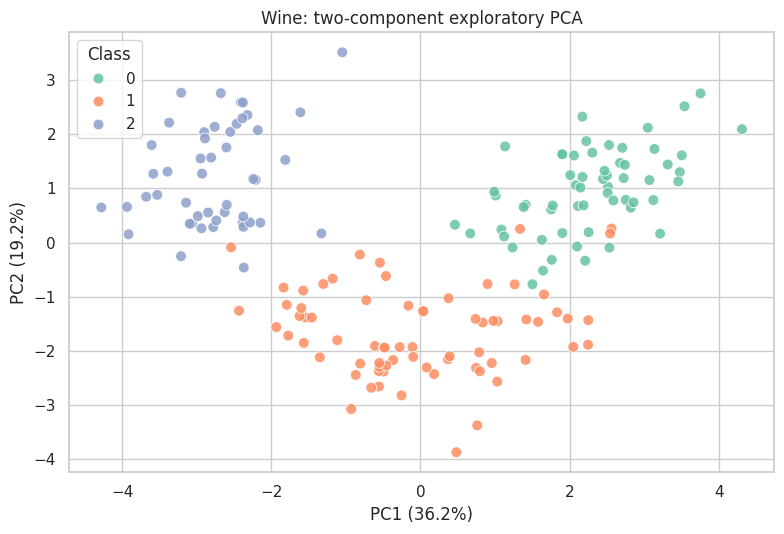

Wine summary: tuned 5-fold CV accuracy 97.0%; independent test accuracy 95.6%.


In [6]:
plot_prep = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
X_wine_scaled_for_plot = plot_prep.fit_transform(X_wine)
wine_pca_plot = PCA(n_components=2, random_state=RANDOM_STATE)
wine_2d = wine_pca_plot.fit_transform(X_wine_scaled_for_plot)
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.scatterplot(x=wine_2d[:, 0], y=wine_2d[:, 1], hue=label_encoder.inverse_transform(y_wine),
                palette="Set2", alpha=.85, s=60, ax=ax)
ax.set(xlabel=f"PC1 ({wine_pca_plot.explained_variance_ratio_[0]:.1%})",
       ylabel=f"PC2 ({wine_pca_plot.explained_variance_ratio_[1]:.1%})",
       title="Wine: two-component exploratory PCA")
ax.legend(title="Class")
plt.tight_layout()
plt.show()
print(f"Wine summary: tuned 5-fold CV accuracy {grid_search.best_score_:.1%}; independent test accuracy {wine_test_accuracy:.1%}.")

## 4. Agricultural feed recommendation using PCA and cosine similarity

The Chickwts dataset contains chicken weights and six categorical feed types. The numerical `weight` feature is standardized and transformed using **PCA with one principal component (PC1)**. Feed-level profiles are generated by aggregating the PC1 scores for each feed category.

**Cosine similarity** is calculated between the feed-level PC1 vectors. Because the representation contains only one dimension, cosine similarity generally produces values of **+1 or −1** for nonzero vectors; these values indicate direction rather than magnitude. **Absolute PC1 distance** is therefore used as a secondary ranking criterion to distinguish feeds tied on cosine similarity. The combined ranking is exploratory and should not be interpreted as a validated recommendation based on nutrition or production costs.

Standardized chicken weight mean: -0.000000; std: 1.000000
Explained variance with one PCA component: 100.0%
Feed-level profile (mean PC1 used for cosine):


,count,mean_weight,sd_weight,mean_PC1
feed,,,,
casein,12,323.583,64.434,0.803
horsebean,10,160.200,38.626,-1.304
linseed,12,218.750,52.236,-0.549
meatmeal,11,276.909,64.901,0.201
soybean,14,246.429,54.129,-0.192
sunflower,12,328.917,48.836,0.872


Cosine similarities between all feed categories:


,casein,horsebean,linseed,meatmeal,soybean,sunflower
casein,1.0,-1.0,-1.0,1.0,-1.0,1.0
horsebean,-1.0,1.0,1.0,-1.0,1.0,-1.0
linseed,-1.0,1.0,1.0,-1.0,1.0,-1.0
meatmeal,1.0,-1.0,-1.0,1.0,-1.0,1.0
soybean,-1.0,1.0,1.0,-1.0,1.0,-1.0
sunflower,1.0,-1.0,-1.0,1.0,-1.0,1.0


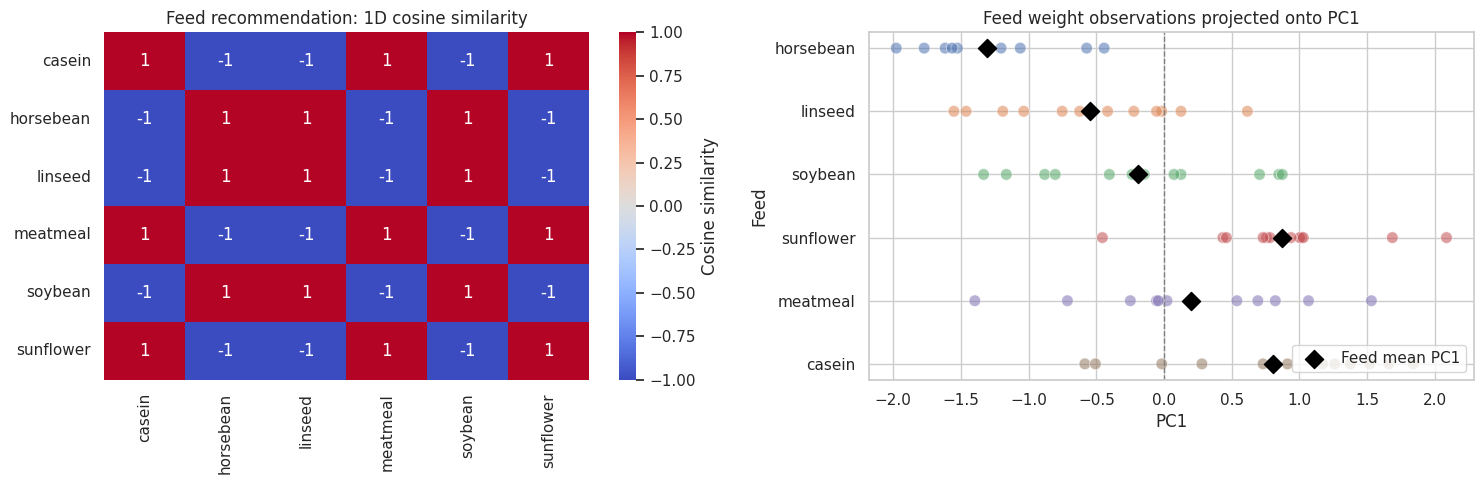

In [7]:
# Feed labels are identities to compare, not numerical predictors to impute or scale.
weight_imputer = SimpleImputer(strategy="median")
weight_clean = weight_imputer.fit_transform(chick[["weight"]])
weight_scaler = StandardScaler()
weight_scaled = weight_scaler.fit_transform(weight_clean)
feed_pca = PCA(n_components=1)
feed_pc1 = feed_pca.fit_transform(weight_scaled)

chick_prepared = chick.copy()
chick_prepared["weight_standardized"] = weight_scaled.ravel()
chick_prepared["PC1"] = feed_pc1.ravel()
print(f"Standardized chicken weight mean: {weight_scaled.mean():.6f}; std: {weight_scaled.std(ddof=0):.6f}")
print(f"Explained variance with one PCA component: {feed_pca.explained_variance_ratio_[0]:.1%}")
assert np.isclose(feed_pca.explained_variance_ratio_[0], 1.0)

# Aggregate scores at feed level so feed identities, not individual birds, are recommended.
feed_profiles = (chick_prepared.groupby("feed", sort=True)
    .agg(count=("weight", "size"), mean_weight=("weight", "mean"),
         sd_weight=("weight", "std"), mean_PC1=("PC1", "mean"))
)
feed_names = feed_profiles.index.tolist()
feed_vectors = feed_profiles[["mean_PC1"]].to_numpy()
feed_cosine = cosine_similarity(feed_vectors)
feed_cosine_df = pd.DataFrame(feed_cosine, index=feed_names, columns=feed_names)
print("Feed-level profile (mean PC1 used for cosine):")
display(feed_profiles.round(3))
print("Cosine similarities between all feed categories:")
display(feed_cosine_df.round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(feed_cosine_df, annot=True, fmt=".0f", vmin=-1, vmax=1,
            cmap="coolwarm", cbar_kws={"label": "Cosine similarity"}, ax=axes[0])
axes[0].set(title="Feed recommendation: 1D cosine similarity")
sns.scatterplot(data=chick_prepared, x="PC1", y="feed", hue="feed", alpha=.55,
                legend=False, s=70, ax=axes[1])
axes[1].scatter(feed_profiles["mean_PC1"], feed_profiles.index,
                marker="D", s=85, c="black", label="Feed mean PC1", zorder=5)
axes[1].axvline(0, color="gray", linestyle="--", linewidth=1)
axes[1].set(title="Feed weight observations projected onto PC1", ylabel="Feed")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

### 4.1 Feed similarity and recommendations

The recommendation function excludes the queried feed and ranks alternatives by **cosine similarity**, followed by **absolute PC1 distance** to resolve ties. The accompanying similarity matrix and feed-level summary statistics make the ranking interpretable.

For example, the soybean feed profile is ranked closest to linseed among alternatives with an equivalent cosine score. These recommendations indicate similarity in **observed weight patterns**, not evidence that substituting one feed for another will produce equivalent outcomes.

In [8]:
def recommend_feeds(feed_name, top_n=3):
    """Show alternative feeds; rank by cosine score, then PC1 proximity for ties."""
    if feed_name not in feed_names:
        raise ValueError(f"Unknown feed {feed_name!r}. Choose from {feed_names}")
    i = feed_names.index(feed_name)
    rows = []
    for j, alternative in enumerate(feed_names):
        if j == i:
            continue
        rows.append({
            "Current feed": feed_name,
            "Recommended alternative": alternative,
            "Cosine similarity": float(feed_cosine[i, j]),
            "Absolute PC1 distance": float(abs(feed_vectors[i, 0] - feed_vectors[j, 0])),
            "Alternative mean weight": float(feed_profiles.loc[alternative, "mean_weight"]),
        })
    order = pd.DataFrame(rows).sort_values(
        ["Cosine similarity", "Absolute PC1 distance", "Recommended alternative"],
        ascending=[False, True, True], kind="stable"
    ).head(top_n)
    return order.reset_index(drop=True)

all_recommendations = pd.concat([recommend_feeds(feed, top_n=3)
                                  for feed in feed_names], ignore_index=True)
print("Top 3 alternative feeds for each source feed (cosine first, proximity tie-breaker):")
display(all_recommendations.round(3))
print("\nWorked example — feeds most comparable to 'soybean':")
display(recommend_feeds("soybean").round(3))
print("Interpretation: values of +1 and -1 are a 1D cosine degeneracy, not strong proof of feed equivalence.")

Top 3 alternative feeds for each source feed (cosine first, proximity tie-breaker):


,Current feed,Recommended alternative,Cosine similarity,Absolute PC1 distance,Alternative mean weight
0,casein,sunflower,1.0,0.069,328.917
1,casein,meatmeal,1.0,0.602,276.909
2,casein,soybean,-1.0,0.995,246.429
3,horsebean,linseed,1.0,0.755,218.750
4,horsebean,soybean,1.0,1.112,246.429
5,horsebean,meatmeal,-1.0,1.505,276.909
6,linseed,soybean,1.0,0.357,246.429
7,linseed,horsebean,1.0,0.755,160.200
8,linseed,meatmeal,-1.0,0.750,276.909
9,meatmeal,casein,1.0,0.602,323.583



Worked example — feeds most comparable to 'soybean':


,Current feed,Recommended alternative,Cosine similarity,Absolute PC1 distance,Alternative mean weight
0,soybean,linseed,1.0,0.357,218.750
1,soybean,horsebean,1.0,1.112,160.200
2,soybean,meatmeal,-1.0,0.393,276.909


Interpretation: values of +1 and -1 are a 1D cosine degeneracy, not strong proof of feed equivalence.


## 5. Regional crime pattern analysis: clustering

The **USArrests** dataset contains four numerical variables for 50 U.S. states: `Murder`, `Assault`, `UrbanPop`, and `Rape`. State names serve as identifiers and are excluded from model fitting.

Following standardization, **PCA loading contributions** are used to rank the original features. The three highest-ranked variables are selected, then reduced to **two principal components (PC1 and PC2)** for clustering. The analysis compares **K-Means** (hard cluster assignments) and **Gaussian Mixture Models (GMM)** (probabilistic assignments).

Feature contributions summarize explained variation, not causal relationships with crime.

In [9]:
state_names = arrests["rownames"].astype(str).reset_index(drop=True)
crime_features = ["Murder", "Assault", "UrbanPop", "Rape"]
crime_raw = arrests[crime_features]
crime_imputer = SimpleImputer(strategy="median")
crime_clean = crime_imputer.fit_transform(crime_raw)
crime_scaler = StandardScaler()
crime_scaled_full = crime_scaler.fit_transform(crime_clean)

# Rank features on standardized, not raw-scale, values.
ranking_pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(crime_scaled_full)
importance = (np.abs(ranking_pca.components_.T)
              @ ranking_pca.explained_variance_ratio_)
feature_rank = pd.DataFrame({"Feature": crime_features,
                             "Weighted absolute PCA loading": importance}).sort_values(
    "Weighted absolute PCA loading", ascending=False, kind="stable"
)
selected_features = feature_rank.head(3)["Feature"].tolist()
print("Unsupervised PCA-loading feature relevance ranking:")
display(feature_rank.round(4))
print("Top 3 selected features:", selected_features)

selected_crime = crime_raw[selected_features]
selected_imputer = SimpleImputer(strategy="median")
selected_scaler = StandardScaler()
crime_selected_scaled = selected_scaler.fit_transform(selected_imputer.fit_transform(selected_crime))
crime_pca = PCA(n_components=2, random_state=RANDOM_STATE)
crime_2d = crime_pca.fit_transform(crime_selected_scaled)
print("Crime PCA explained variance per component:",
      np.round(crime_pca.explained_variance_ratio_, 4))
print(f"Variance retained with 2 PCs: {crime_pca.explained_variance_ratio_.sum():.1%}")
assert crime_2d.shape == (len(arrests), 2)

crime_proj = pd.DataFrame(crime_2d, columns=["PC1", "PC2"])
crime_proj.insert(0, "State", state_names)
display(crime_proj.head(8).round(3))

Unsupervised PCA-loading feature relevance ranking:


,Feature,Weighted absolute PCA loading
0,Murder,0.4358
1,Assault,0.4081
2,UrbanPop,0.3885
3,Rape,0.3784


Top 3 selected features: ['Murder', 'Assault', 'UrbanPop']
Crime PCA explained variance per component: [0.6217 0.3198]
Variance retained with 2 PCs: 94.2%


,State,PC1,PC2
0,Alabama,1.251,-0.934
1,Alaska,0.801,-1.394
2,Arizona,1.354,0.837
3,Arkansas,0.035,-1.118
4,California,1.543,1.518
5,Colorado,0.526,0.792
6,Connecticut,-0.998,1.125
7,Delaware,0.394,0.507


### 5.1 K-Means model selection: elbow method and silhouette score

K-Means models are evaluated across **k = 2–8** using **within-cluster sum of squares (WCSS/inertia)** and the **silhouette score**. The elbow heuristic suggests **k = 4**, while the maximum silhouette score occurs at **k = 2**. Both diagnostics are reported to make this disagreement explicit.

The four-cluster solution is retained for exploratory analysis of more granular state-level profiles. Cluster count selection should be interpreted as a modeling choice rather than evidence of objectively defined regional categories.

K-Means model selection table:


,K,Inertia,Silhouette,Elbow distance
0,2,69.997,0.432,0.000
1,3,46.928,0.392,0.170
2,4,29.938,0.425,0.264
3,5,23.746,0.402,0.224
4,6,19.382,0.401,0.160
5,7,16.575,0.385,0.077
6,8,13.324,0.380,0.000


Selected K-Means k (elbow): 4; corresponding silhouette: 0.425
Highest silhouette occurs at k=2; the elbow and silhouette approaches do not give the same choice.


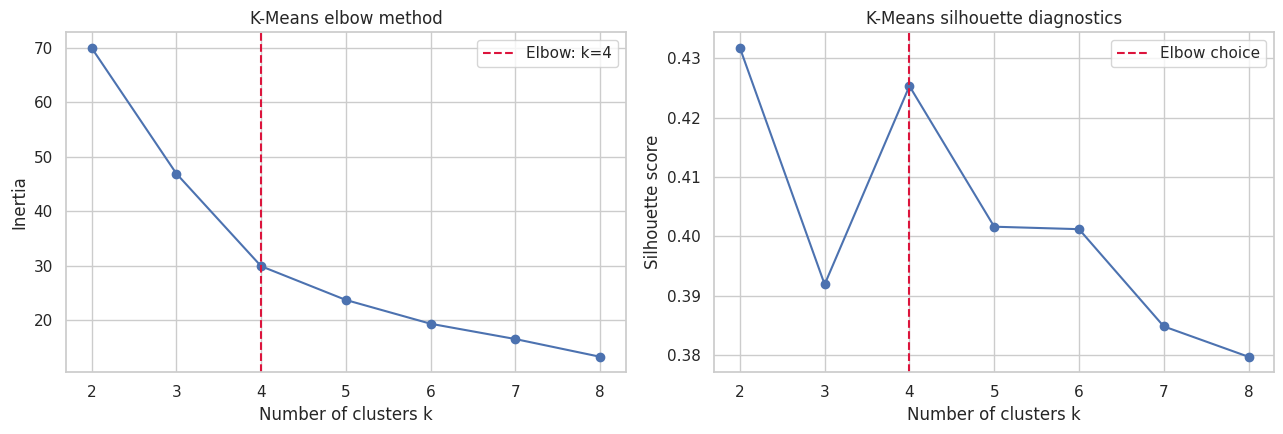

In [10]:
k_values = np.arange(2, 9)
inertias, kmeans_silhouettes = [], []
for k in k_values:
    model = KMeans(n_clusters=int(k), random_state=RANDOM_STATE, n_init=20)
    labels = model.fit_predict(crime_2d)
    inertias.append(float(model.inertia_))
    kmeans_silhouettes.append(float(silhouette_score(crime_2d, labels)))

# Perpendicular distance to line joining first and last points on the elbow curve.
xy = np.column_stack([k_values.astype(float), np.array(inertias)])
scaled = (xy - xy.min(axis=0)) / np.maximum(np.ptp(xy, axis=0), 1e-12)
a, b = scaled[0], scaled[-1]
line = b - a
elbow_distances = np.abs(line[0] * (a[1] - scaled[:, 1]) - (a[0] - scaled[:, 0]) * line[1]) / np.linalg.norm(line)
optimal_k = int(k_values[np.argmax(elbow_distances)])
kmeans_selection = pd.DataFrame({"K": k_values, "Inertia": inertias,
                                  "Silhouette": kmeans_silhouettes,
                                  "Elbow distance": elbow_distances})
print("K-Means model selection table:")
display(kmeans_selection.round(3))
print(f"Selected K-Means k (elbow): {optimal_k}; corresponding silhouette: "
      f"{kmeans_silhouettes[list(k_values).index(optimal_k)]:.3f}")
print(f"Highest silhouette occurs at k={k_values[np.argmax(kmeans_silhouettes)]}; "
      "the elbow and silhouette approaches do not give the same choice.")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(k_values, inertias, marker="o")
axes[0].axvline(optimal_k, linestyle="--", color="crimson", label=f"Elbow: k={optimal_k}")
axes[0].set(title="K-Means elbow method", xlabel="Number of clusters k", ylabel="Inertia")
axes[0].legend()
axes[1].plot(k_values, kmeans_silhouettes, marker="o")
axes[1].axvline(optimal_k, linestyle="--", color="crimson", label="Elbow choice")
axes[1].set(title="K-Means silhouette diagnostics", xlabel="Number of clusters k", ylabel="Silhouette score")
axes[1].legend()
plt.tight_layout()
plt.show()

### 5.2 Gaussian Mixture Model selection using BIC

Gaussian Mixture Models (**GMMs**) are evaluated with different component counts and covariance structures. The **Bayesian Information Criterion (BIC)** balances goodness of fit against model complexity, with smaller values preferred. The **Akaike Information Criterion (AIC)** is also displayed for context.

The **global BIC minimum corresponds to one component**, indicating limited evidence for separate Gaussian clusters in the two-dimensional representation. For comparison against the K-Means partition, the best BIC model constrained to **at least two components** is also evaluated; this produces a **two-component exploratory GMM**. The constrained solution is not presented as the overall BIC optimum.

GMM configurations ranked by BIC (lower is better):


,components,covariance,BIC,AIC
0,1,diag,328.53,320.88
1,1,full,332.44,322.88
2,2,diag,333.56,316.35
3,2,full,335.06,314.03
4,3,diag,341.12,314.35
5,5,diag,347.49,301.60
6,3,full,351.22,318.72
7,4,diag,357.52,321.19
8,6,diag,362.69,307.24
9,5,full,364.62,309.17


Unrestricted BIC optimum: 1 component(s), diag covariance, BIC 328.53
Best BIC **among multi-cluster GMMs**: 2 components, diag covariance, BIC 333.56
CAUTION: The unrestricted BIC favors ONE group; treating the conditional two-or-more group solution as exploratory is necessary. The evidence for GMM separation is weak.


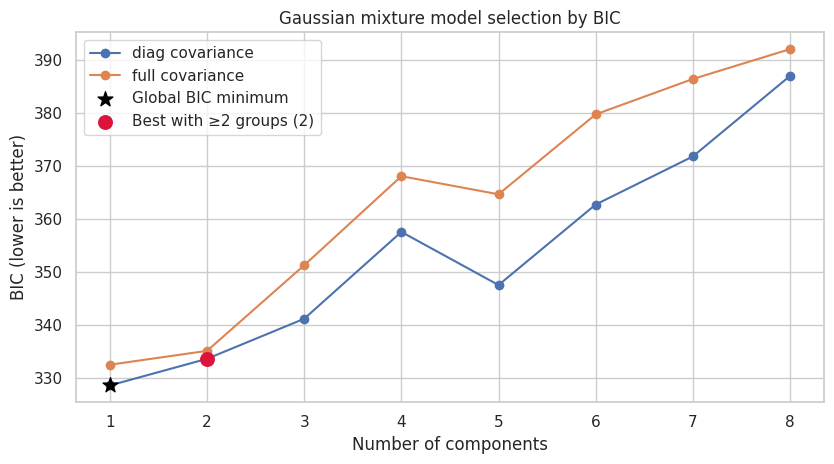

In [11]:
gmm_records = []
for covariance in ["full", "diag"]:
    for n in range(1, 9):
        candidate = GaussianMixture(
            n_components=n, covariance_type=covariance, random_state=RANDOM_STATE,
            n_init=5, max_iter=300, reg_covar=1e-4
        )
        candidate.fit(crime_2d)
        gmm_records.append({"components": n, "covariance": covariance,
                            "BIC": candidate.bic(crime_2d),
                            "AIC": candidate.aic(crime_2d)})
gmm_selection = pd.DataFrame(gmm_records).sort_values("BIC").reset_index(drop=True)
unrestricted_best_gmm = gmm_selection.iloc[0]
# Also inspect the best solution with two or more groups for comparison.
multicluster_gmm_selection = gmm_selection.loc[gmm_selection["components"] >= 2]
best_gmm_spec = multicluster_gmm_selection.iloc[0]
optimal_gmm = int(best_gmm_spec["components"])
best_covariance = str(best_gmm_spec["covariance"])
print("GMM configurations ranked by BIC (lower is better):")
display(gmm_selection.head(12).round(2))
print(f"Unrestricted BIC optimum: {int(unrestricted_best_gmm['components'])} component(s), "
      f"{unrestricted_best_gmm['covariance']} covariance, BIC {unrestricted_best_gmm['BIC']:.2f}")
print(f"Best BIC **among multi-cluster GMMs**: {optimal_gmm} components, "
      f"{best_covariance} covariance, BIC {best_gmm_spec['BIC']:.2f}")
if int(unrestricted_best_gmm["components"]) == 1:
    print("CAUTION: The unrestricted BIC favors ONE group; treating the conditional two-or-more "
          "group solution as exploratory is necessary. The evidence for GMM separation is weak.")

fig, ax = plt.subplots(figsize=(8.5, 4.8))
for form, group in gmm_selection.groupby("covariance"):
    vals = group.sort_values("components")
    ax.plot(vals["components"], vals["BIC"], marker="o", label=f"{form} covariance")
ax.scatter([int(unrestricted_best_gmm["components"])], [unrestricted_best_gmm["BIC"]],
           color="black", marker="*", s=125, zorder=6, label="Global BIC minimum")
ax.scatter([optimal_gmm], [best_gmm_spec["BIC"]], color="crimson", s=95, zorder=5,
           label=f"Best with ≥2 groups ({optimal_gmm})")
ax.set(title="Gaussian mixture model selection by BIC", xlabel="Number of components", ylabel="BIC (lower is better)")
ax.legend()
plt.tight_layout()
plt.show()

### 5.3 Comparing K-Means and GMM

**K-Means** assigns each state to exactly one cluster. **GMM** estimates cluster membership probabilities and assigns the state to its highest-probability component. Two-dimensional PCA scatterplots display the partitions side by side.

The **silhouette score** assesses cluster separation, while the **Adjusted Rand Index (ARI)** quantifies agreement between the two label assignments. Cluster identifiers are arbitrary and are not directly comparable by their numerical labels.

Clustering comparison (silhouette higher is better, when defined):


,Model,Selected groups,Selection,Silhouette,Probabilities available
0,K-Means,4,Elbow (inertia),0.425,No
1,GMM,2,Min BIC for ≥2 groups,0.442,Yes


Adjusted Rand index comparing K-Means vs. GMM partitions: 0.440


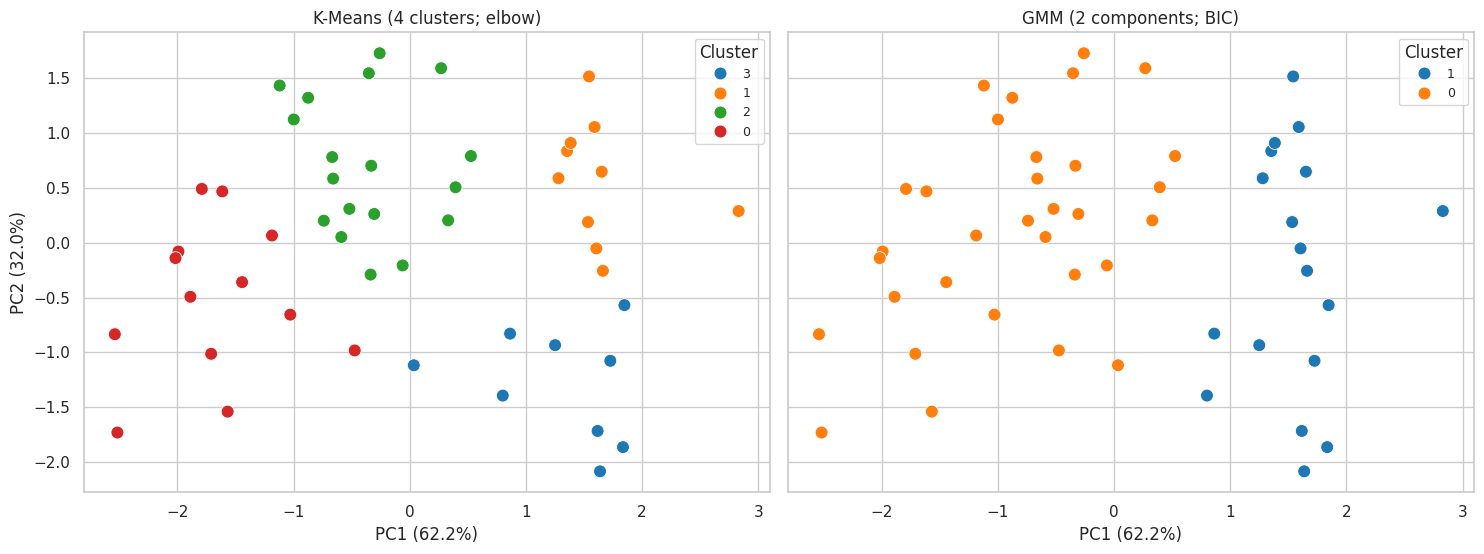

In [12]:
kmeans_final = KMeans(n_clusters=optimal_k, random_state=RANDOM_STATE, n_init=20)
kmeans_labels = kmeans_final.fit_predict(crime_2d)
gmm_final = GaussianMixture(n_components=optimal_gmm, covariance_type=best_covariance,
                            random_state=RANDOM_STATE, n_init=5, max_iter=300, reg_covar=1e-4)
gmm_final.fit(crime_2d)
gmm_labels = gmm_final.predict(crime_2d)
gmm_probs = gmm_final.predict_proba(crime_2d)
gmm_confidence = gmm_probs.max(axis=1)

crime_results = arrests[["rownames"] + crime_features].copy().rename(columns={"rownames": "State"})
crime_results[["PC1", "PC2"]] = crime_2d
crime_results["KMeans cluster"] = kmeans_labels
crime_results["GMM cluster"] = gmm_labels
crime_results["GMM probability"] = gmm_confidence

km_silhouette = float(silhouette_score(crime_2d, kmeans_labels)) if optimal_k >= 2 else float("nan")
gmm_silhouette = (float(silhouette_score(crime_2d, gmm_labels))
                  if len(np.unique(gmm_labels)) > 1 else float("nan"))
ari = float(adjusted_rand_score(kmeans_labels, gmm_labels))
comparison = pd.DataFrame([
    {"Model": "K-Means", "Selected groups": optimal_k, "Selection": "Elbow (inertia)",
     "Silhouette": km_silhouette, "Probabilities available": "No"},
    {"Model": "GMM", "Selected groups": optimal_gmm, "Selection": "Min BIC for ≥2 groups",
     "Silhouette": gmm_silhouette, "Probabilities available": "Yes"},
])
print("Clustering comparison (silhouette higher is better, when defined):")
display(comparison.round(3))
print(f"Adjusted Rand index comparing K-Means vs. GMM partitions: {ari:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.7), sharex=True, sharey=True)
for ax, labels, title in [
    (axes[0], kmeans_labels, f"K-Means ({optimal_k} clusters; elbow)"),
    (axes[1], gmm_labels, f"GMM ({optimal_gmm} components; BIC)")]:
    sns.scatterplot(x=crime_2d[:, 0], y=crime_2d[:, 1], hue=labels.astype(str),
                    palette="tab10", s=86, edgecolor="white", linewidth=.6, ax=ax)
    ax.set(title=title,
           xlabel=f"PC1 ({crime_pca.explained_variance_ratio_[0]:.1%})",
           ylabel=f"PC2 ({crime_pca.explained_variance_ratio_[1]:.1%})")
    ax.legend(title="Cluster", loc="best", fontsize=9)
plt.tight_layout()
plt.show()

### 5.4 Cluster profiles and interpretation

Cluster profiles report mean values of the original crime indicators for each K-Means and GMM group. Standardized means support cross-feature comparisons, while the state membership table provides geographic context. For GMM, the maximum posterior probability indicates assignment confidence.

These profiles describe statistical associations in the historical dataset. Neither PCA loadings nor unsupervised cluster membership identifies causes of crime or establishes current regional risk.

K-Means cluster membership counts:


,states
KMeans cluster,
0,13
1,10
2,18
3,9


K-Means cluster profile: original-unit average of all four features:


,Murder,Assault,UrbanPop,Rape
KMeans cluster,,,,
0,3.60,78.54,52.08,12.18
1,11.37,270.10,79.20,32.01
2,5.97,144.67,73.89,20.41
3,13.50,245.78,53.11,23.98


GMM cluster profile: original-unit average of all four features:


,Murder,Assault,UrbanPop,Rape
GMM cluster,,,,
0,5.09,119.22,64.28,17.04
1,12.58,262.39,67.78,28.69


How cluster assignments agree (counts, label numbers are not aligned):


GMM cluster,0,1
KMeans cluster,,
0,13,0
1,0,10
2,18,0
3,1,8


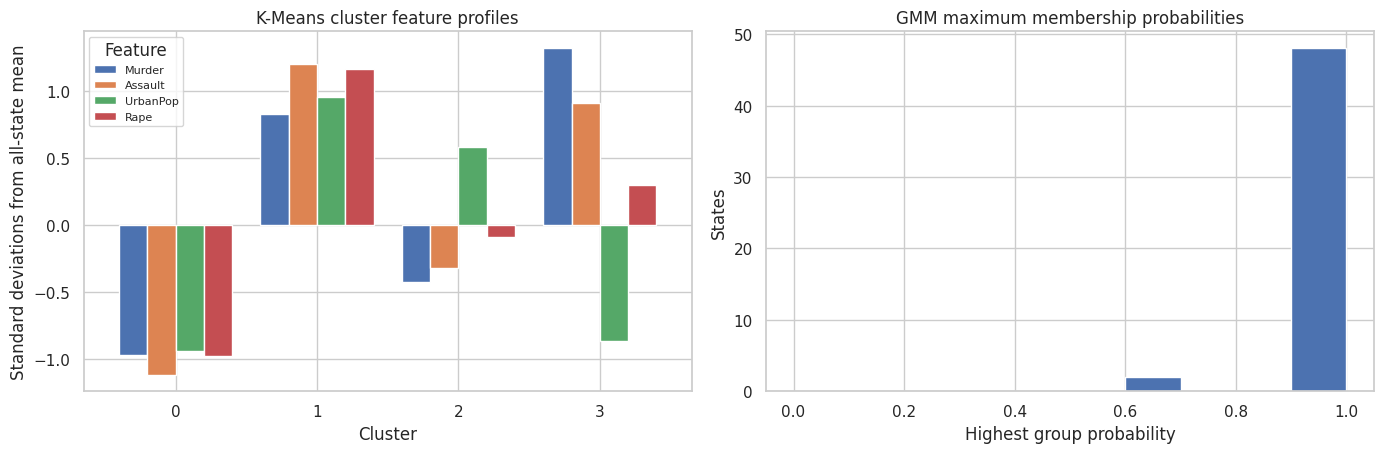

States in each K-Means group:
  Cluster 0 (13 states): Idaho, Iowa, Kentucky, Maine, Minnesota, Montana, Nebraska, New Hampshire, North Dakota, South Dakota, Vermont, West Virginia, Wisconsin
  Cluster 1 (10 states): Arizona, California, Florida, Illinois, Maryland, Michigan, Nevada, New Mexico, New York, Texas
  Cluster 2 (18 states): Colorado, Connecticut, Delaware, Hawaii, Indiana, Kansas, Massachusetts, Missouri, New Jersey, Ohio, Oklahoma, Oregon, Pennsylvania, Rhode Island, Utah, Virginia, Washington, Wyoming
  Cluster 3 (9 states): Alabama, Alaska, Arkansas, Georgia, Louisiana, Mississippi, North Carolina, South Carolina, Tennessee

Lowest-confidence GMM assignments:


,State,KMeans cluster,GMM cluster,GMM probability
41,Tennessee,3,1,0.665
1,Alaska,3,1,0.672
5,Colorado,2,0,0.902
42,Texas,1,1,0.907
2,Arizona,1,1,0.928
12,Illinois,1,1,0.936
0,Alabama,3,1,0.942
7,Delaware,2,0,0.962
4,California,1,1,0.963
21,Michigan,1,1,0.965



Stakeholder interpretation — which descriptive K-Means groups lead each indicator?
  Murder: highest average in group 3 (13.50); lowest in group 0 (3.60).
  Assault: highest average in group 1 (270.10); lowest in group 0 (78.54).
  UrbanPop: highest average in group 1 (79.20); lowest in group 0 (52.08).
  Rape: highest average in group 1 (32.01); lowest in group 0 (12.18).
GMM captures a coarser probabilistic grouping; because unrestricted BIC prefers one component, treat its two-group result as exploratory.


In [13]:
print("K-Means cluster membership counts:")
display(crime_results["KMeans cluster"].value_counts().sort_index().rename("states").to_frame())
print("K-Means cluster profile: original-unit average of all four features:")
kmeans_profile = crime_results.groupby("KMeans cluster")[crime_features].mean().round(2)
display(kmeans_profile)
print("GMM cluster profile: original-unit average of all four features:")
gmm_profile = crime_results.groupby("GMM cluster")[crime_features].mean().round(2)
display(gmm_profile)
print("How cluster assignments agree (counts, label numbers are not aligned):")
display(pd.crosstab(crime_results["KMeans cluster"], crime_results["GMM cluster"]))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.7))
# Standardized means across all four numeric variables make profiles easier to compare on one axis.
standardized_profile = crime_results.groupby("KMeans cluster")[crime_features].mean()
standardized_profile = (standardized_profile - crime_raw.mean()) / crime_raw.std(ddof=0)
standardized_profile.plot(kind="bar", ax=axes[0], width=.8)
axes[0].set(title="K-Means cluster feature profiles", xlabel="Cluster", ylabel="Standard deviations from all-state mean")
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(title="Feature", fontsize=8)
axes[1].hist(gmm_confidence, bins=np.linspace(0, 1, 11), edgecolor="white")
axes[1].set(title="GMM maximum membership probabilities", xlabel="Highest group probability", ylabel="States")
plt.tight_layout()
plt.show()

print("States in each K-Means group:")
for label in sorted(crime_results["KMeans cluster"].unique()):
    states = crime_results.loc[crime_results["KMeans cluster"] == label, "State"].sort_values().tolist()
    print(f"  Cluster {label} ({len(states)} states): {', '.join(states)}")
print("\nLowest-confidence GMM assignments:")
display(crime_results.sort_values("GMM probability").head(10)[
    ["State", "KMeans cluster", "GMM cluster", "GMM probability"]].round(3))

print("\nStakeholder interpretation — which descriptive K-Means groups lead each indicator?")
for indicator in crime_features:
    top_id = int(kmeans_profile[indicator].idxmax())
    low_id = int(kmeans_profile[indicator].idxmin())
    print(f"  {indicator}: highest average in group {top_id} "
          f"({kmeans_profile.loc[top_id, indicator]:.2f}); lowest in group {low_id} "
          f"({kmeans_profile.loc[low_id, indicator]:.2f}).")
print("GMM captures a coarser probabilistic grouping; because unrestricted BIC "
      "prefers one component, treat its two-group result as exploratory.")

## 6. Results and discussion

The final output consolidates classification metrics, feed recommendation diagnostics, and clustering results.

The **PCA + tuned k-NN** classifier achieves strong performance on the Wine test set, although generalization to new inventory requires further testing. The **feed recommender** satisfies the PCA and cosine-similarity methodology but remains constrained by a single numerical feature; PC1 distance is included to improve ranking resolution. For **USArrests**, the K-Means elbow and silhouette diagnostics differ, and unrestricted GMM BIC favors a single component, limiting confidence in distinct Gaussian clusters.

Further validation would benefit from independent wine batches, additional feed variables (including nutritional composition and cost), and more recent comparable crime statistics.

In [14]:
most_distant_feed = float(np.abs(feed_vectors[:, None, :] - feed_vectors[None, :, :]).max())
print("DATAVINE ANALYTICS — RESULTS")
print("=" * 66)
print("1) Wine classification")
print(f"   {len(wine)} wines; {X_wine.shape[1]} features; {len(label_encoder.classes_)} classes.")
print(f"   5-fold tuned CV accuracy: {grid_search.best_score_:.1%}.")
print(f"   Independent test accuracy: {wine_test_accuracy:.1%} ({len(y_test)} test wines).")
print(f"   k-NN settings: {grid_search.best_params_}; PCA: {wine_best.named_steps['pca'].n_components_} "
      f"components retaining {retained:.1%} of variance.")
print("2) Agricultural feed recommendations")
print(f"   {len(chick)} birds; {len(feed_names)} feed categories. PCA(1) retains "
      f"{feed_pca.explained_variance_ratio_[0]:.1%} variance.")
print("   Cosine similarity is shown alongside 1D PCA distance to resolve ties.")
print("   Caution: observational weights are not causal evidence of feed effects.")
print("3) Regional crime patterns")
print(f"   {len(arrests)} states; selected features: {', '.join(selected_features)}.")
print(f"   K-Means elbow k={optimal_k} (silhouette {km_silhouette:.3f}); "
      f"GMM multi-cluster BIC selection={optimal_gmm} (silhouette {gmm_silhouette:.3f}).")
print(f"   Unrestricted GMM BIC minimum: {int(unrestricted_best_gmm['components'])} "
      "group(s); interpret multi-cluster GMM cautiously if it differs.")
print(f"   Model partition agreement (ARI): {ari:.3f}.")
print("   Caution: clusters describe historical association, not causes or current crime risk.")
print("=" * 66)
print("Suggested next steps: validate wine classifier on new distributor batches; "
      "collect controlled feed trials with cost and nutrition; use current, comparable "
      "state-level crime data before policy deployment.")

DATAVINE ANALYTICS — RESULTS
1) Wine classification
   178 wines; 13 features; 3 classes.
   5-fold tuned CV accuracy: 97.0%.
   Independent test accuracy: 95.6% (45 test wines).
   k-NN settings: {'knn__metric': 'euclidean', 'knn__n_neighbors': 1, 'knn__weights': 'uniform'}; PCA: 10 components retaining 96.4% of variance.
2) Agricultural feed recommendations
   71 birds; 6 feed categories. PCA(1) retains 100.0% variance.
   Cosine similarity is shown alongside 1D PCA distance to resolve ties.
   Caution: observational weights are not causal evidence of feed effects.
3) Regional crime patterns
   50 states; selected features: Murder, Assault, UrbanPop.
   K-Means elbow k=4 (silhouette 0.425); GMM multi-cluster BIC selection=2 (silhouette 0.442).
   Unrestricted GMM BIC minimum: 1 group(s); interpret multi-cluster GMM cautiously if it differs.
   Model partition agreement (ARI): 0.440.
   Caution: clusters describe historical association, not causes or current crime risk.
Suggested next

### Reproducibility

The notebook expects `wine.csv`, `chickwts.csv`, and `USArrests.csv` in the same directory. Install the dependencies listed in `requirements.txt`, launch Jupyter, and select **Restart Kernel and Run All Cells**. The notebook contains saved outputs, including data summaries, evaluation metrics, and visualizations.